# Лекція 4. Трансформери та мовні моделі.

## 0. Налаштування середовища

### 0.0. Імпортуємо бібліотеки

In [20]:
pip install "transformers[sentencepiece]==5.18.0" datasets evaluate gradio tensorboard matplotlib pandas psutil

  Using cached transformers-5.18.0-py3-none-any.whl.metadata (32 kB)
  Using cached evaluate-0.4.6-py3-none-any.whl.metadata (9.5 kB)
  Using cached gradio-6.32.0-py3-none-any.whl.metadata (16 kB)
  Using cached gradio_client-2.7.2-py3-none-any.whl.metadata (7.1 kB)
  Using cached hf_gradio-0.4.1-py3-none-any.whl.metadata (428 bytes)
  Using cached safehttpx-0.1.7-py3-none-any.whl.metadata (4.2 kB)
  Using cached aiohttp-3.14.5-cp311-cp311-win_amd64.whl.metadata (8.5 kB)
Using cached transformers-5.18.0-py3-none-any.whl (12.6 MB)
Using cached evaluate-0.4.6-py3-none-any.whl (84 kB)
Using cached gradio-6.32.0-py3-none-any.whl (31.4 MB)
Using cached gradio_client-2.7.2-py3-none-any.whl (64 kB)
Using cached hf_gradio-0.4.1-py3-none-any.whl (4.5 kB)
Using cached safehttpx-0.1.7-py3-none-any.whl (9.0 kB)
Using cached aiohttp-3.14.5-cp311-cp311-win_amd64.whl (512 kB)

   ----------- ---------------------------- 2/7 [gradio-client]
  Attempting uninstall: transformers
   ----------- ---------

  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.


  Using cached groovy-0.1.2-py3-none-any.whl.metadata (6.1 kB)
  Using cached hf_gradio-0.4.1-py3-none-any.whl.metadata (428 bytes)
  Using cached httpx-0.28.1-py3-none-any.whl.metadata (7.1 kB)
  Using cached pydub-0.25.1-py2.py3-none-any.whl.metadata (1.4 kB)
  Using cached safehttpx-0.1.7-py3-none-any.whl.metadata (4.2 kB)
  Using cached semantic_version-2.10.0-py2.py3-none-any.whl.metadata (9.7 kB)
  Using cached tomlkit-0.14.0-py3-none-any.whl.metadata (2.8 kB)
  Using cached uvicorn-0.54.0-py3-none-any.whl.metadata (6.6 kB)
  Using cached httpcore-1.0.9-py3-none-any.whl.metadata (21 kB)
   ---------------------------------------- 0.0/12.6 MB ? eta -:--:--
   --------- ------------------------------ 2.9/12.6 MB 21.0 MB/s eta 0:00:01
   ---------------------------------------- 12.6/12.6 MB 37.4 MB/s  0:00:00
   ---------------------------------------- 0.0/31.4 MB ? eta -:--:--
   -------------------- ------------------- 16.0/31.4 MB 77.5 MB/s eta 0:00:01
   ------------------------

  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress t

In [1]:
import sys
import os
import math
import time

import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F

### 0.1. Перевіряємо чи ми точно в Colab

In [ ]:
IN_COLAB = "google.colab" in sys.modules
print("Running in Colab:", IN_COLAB)

assert IN_COLAB, f"Ця лаба має виконуватися в Google Colab (https://colab.research.google.com/)"


### 0.2. Використовуємо графічний прискорювач, якщо доступний.
На Colab зазвичай є безкоштовний GPU (T4).
Використовуємо його, якщо він доступний.
Якщо ні, залишаємося на CPU.

In [11]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Використовуємо:", device)

if device.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))


Використовуємо: cuda
GPU: NVIDIA GeForce RTX 4070 Ti SUPER


### 0.3. Монтуємо Google Drive

Сесія Colab обмежена в часі й може скинутись — усе в `/content` зникає разом
з нею. Монтуємо Drive, щоб чекпоінти mini-GPT й логи TensorBoard пережили
перезапуск.

In [2]:
BASE_DIR = os.path.join(os.getcwd(), "Lab3Runs")
os.makedirs(BASE_DIR, exist_ok=True)

ARTIFACT_DIR = BASE_DIR

RUNS_DIR = os.path.join(BASE_DIR, "runs")
os.makedirs(RUNS_DIR, exist_ok=True)

print(f"Артефакти зберігаються в: {ARTIFACT_DIR}")

Артефакти зберігаються в: d:\Downloads\lab3\Lab3Runs


---
## 1. Корпус: українська поезія

Для mini-GPT з нуля потрібен текстовий корпус однією мовою, достатньо
великий, щоб модель могла вивчити бодай прості закономірності.

Використовуємо датасет [`RudyiVT/ukrainian-poems`](https://huggingface.co/datasets/RudyiVT/ukrainian-poems)
(17 918 віршів, 757 авторів, зібрано з [ukrlib.com.ua](https://www.ukrlib.com.ua/))
повністю — весь текст іде в один суцільний корпус для тренування.

### 1.1. Завантажуємо датасет з Hugging Face Hub

In [3]:
from datasets import load_dataset

poems_dataset = load_dataset("RudyiVT/ukrainian-poems", split="train")
print("Усього віршів у датасеті:", len(poems_dataset))
print("Колонки:", poems_dataset.column_names)


Усього віршів у датасеті: 17918
Колонки: ['author', 'author_url', 'poem_name', 'poem_url', 'context_author', 'context_poem_name', 'context_poem']


### 1.2. Збираємо суцільний корпус

In [4]:
poems_df = poems_dataset.to_pandas()
corpus_text = "\n\n".join(poems_df["context_poem"].dropna().tolist())

print("Розмір корпусу:", len(corpus_text), "символів")
print("Перші 500 символів корпусу:\n", corpus_text[:500])

Розмір корпусу: 60886196 символів
Перші 500 символів корпусу:
 У гостинній бавилися розмовою три добре знайомі особи.

Обі панночки торочили свою звичайну, мляву розмову, мололи дрібними язичками, як на коловороті, закрашували забаву штучними, але пустими дотепами, перекидалися за-мітними поглядами, переплітали невинну розмову більше або менше невинними сплетнями.

Він сидів набоці вигідно у кріслі, слухав оклепаного розговору і банальних дотепів, нудився і... від часу до часу зівав.

Думав свою думку і впертим мовчанням, себто маломов-ністю, в товаристві д


### 1.3. Базова статистика корпусу

In [5]:
words = corpus_text.split()
unique_words = set(w.lower() for w in words)

print("Слів (з повторами):   ", len(words))
print("Унікальних слів:      ", len(unique_words))
print("Приклад уривку:\n")
print(corpus_text[:500])


Слів (з повторами):    9941806
Унікальних слів:       994965
Приклад уривку:

У гостинній бавилися розмовою три добре знайомі особи.

Обі панночки торочили свою звичайну, мляву розмову, мололи дрібними язичками, як на коловороті, закрашували забаву штучними, але пустими дотепами, перекидалися за-мітними поглядами, переплітали невинну розмову більше або менше невинними сплетнями.

Він сидів набоці вигідно у кріслі, слухав оклепаного розговору і банальних дотепів, нудився і... від часу до часу зівав.

Думав свою думку і впертим мовчанням, себто маломов-ністю, в товаристві д


---
## 2. Токенізація: BPE на власному корпусі

Токенізація перетворює текст на послідовність id. Використовуємо BPE (Byte Pair Encoding),
який досить часто використовується на великих LLM. Тренуємо через `tokenizers` (від HuggingFace)—
переписувати цикл злиття пар вручну немає сенсу: це вже готовий, швидкий (Rust) алгоритм,
а не нова концепція, яку ми тут вивчаємо.

### 2.1. Тренуємо BPE

Тренер бачить датасет як список окремих віршів (а не один суцільний
рядок) — це і природніший спосіб виклику `train_from_iterator`, і легший
для пам'яті: не потрібно тримати весь корпус як один текстовий блок під
час підрахунку частот пар.

In [6]:
VOCAB_SIZE = 6000
SPECIAL_TOKENS = ["<unk>", "<eos>"]

from tokenizers import Tokenizer, models, trainers, pre_tokenizers, decoders

bpe_tokenizer = Tokenizer(models.BPE(unk_token="<unk>"))
bpe_tokenizer.pre_tokenizer = pre_tokenizers.ByteLevel(add_prefix_space=False)
bpe_tokenizer.decoder = decoders.ByteLevel()

bpe_trainer = trainers.BpeTrainer(vocab_size=VOCAB_SIZE, special_tokens=SPECIAL_TOKENS)
poems_iterator = poems_df["context_poem"].dropna().tolist()
bpe_tokenizer.train_from_iterator(poems_iterator, trainer=bpe_trainer)
del poems_iterator

bpe_vocab = bpe_tokenizer.get_vocab()
itos = [None] * len(bpe_vocab)
for tok, idx in bpe_vocab.items():
    itos[idx] = tok
stoi = bpe_vocab
UNK_ID = stoi["<unk>"]

def tokenize(text: str) -> list[str]:
    return bpe_tokenizer.encode(text).tokens

def encode(tokens: list[str]) -> list[int]:
    return [stoi.get(t, UNK_ID) for t in tokens]

def decode(ids: list[int]) -> str:
    return bpe_tokenizer.decode(ids)

print("Розмір словника (BPE):", len(itos))

Розмір словника (BPE): 6000


### 2.2. Кодуємо корпус у послідовність id

Кодуємо пачками (`.encode_batch()`) по кілька сотень віршів, одразу перетворюючи кожен
результат на компактний `numpy` масив (`int32`, 4 байти на токен). Один
виклик `encode()` на весь корпус одразу тримає у пам'яті і список токенів,
і список id для всього тексту разом, що може призвести до вичерпання памʼяті (out of memory, OOM).

In [7]:
import gc
import numpy as np

ENCODE_BATCH_SIZE = 1000
EOS_ID = stoi["<eos>"]
poems_list = poems_df["context_poem"].dropna().tolist()

token_id_chunks = []
for start in range(0, len(poems_list), ENCODE_BATCH_SIZE):
    batch = poems_list[start:start + ENCODE_BATCH_SIZE]
    encodings = bpe_tokenizer.encode_batch(batch)
    for enc in encodings:
        # <eos> позначає межу між віршами — без цього при конкатенації
        # останній токен одного вірша впритул стикається з першим токеном
        # наступного, і модель бачить один суцільний текст замість окремих творів.
        token_id_chunks.append(np.array(enc.ids + [EOS_ID], dtype=np.int32))
    del encodings
del poems_list
gc.collect()

token_ids = np.concatenate(token_id_chunks)
del token_id_chunks
gc.collect()

unk_share = (token_ids == UNK_ID).mean()
print(f"Токенів у корпусі (обраний токенізатор): {len(token_ids)}")
print(f"Токенів поза словником (<unk>): {unk_share:.1%}")

data = torch.from_numpy(token_ids.astype(np.int64))
del token_ids
gc.collect()
print("Форма закодованого корпусу:", data.shape)

Токенів у корпусі (обраний токенізатор): 21041508
Токенів поза словником (<unk>): 0.0%
Форма закодованого корпусу: torch.Size([21041508])


### 2.3. Спліт train/val

Для тексту спліт робимо **послідовним** зрізом, а не випадковим
перемішуванням рядків — модель тренується передбачати "наступне слово",
тому послідовність токенів має лишатись цілою.

In [8]:
split_idx = int(len(data) * 0.9)
train_data = data[:split_idx]
val_data = data[split_idx:]

print("train:", train_data.shape, " val:", val_data.shape)


train: torch.Size([18937357])  val: torch.Size([2104151])


---
## 3. Mini-GPT з нуля

Реалізуємо decoder-only трансформер "з нуля" — так, як на слайдах лекції:
Query/Key/Value власноруч, без `nn.MultiheadAttention` як чорної скриньки.

Модель навмисно маленька: мета — побачити механіку і криву навчання,
а не отримати практично корисний генератор тексту. Тренування вкладається
у 1.5-2 години на безкоштовному Colab T4.

### 3.1. Гіперпараметри

In [9]:
CONTEXT_LEN = 64        # скільки попередніх токенів бачить модель
EMBED_DIM = 128         # розмірність embedding
N_HEADS = 4             # кількість attention-голів
N_LAYERS = 4            # кількість блоків трансформера
DROPOUT = 0.1           # рівень dropout для регуляризації
BATCH_SIZE = 64         # розмір батчу
LEARNING_RATE = 3e-4    # швидкість навчання
MAX_ITERS = 8000        # кількість ітерацій навчання
EVAL_INTERVAL = 50     # було 250, інтервал (в ітераціях) для оцінки моделі на валідаційній вибірці
EVAL_ITERS = 50         # кількість ітерацій для оцінки на валідаційній вибірці

assert EMBED_DIM % N_HEADS == 0, "EMBED_DIM має ділитися на N_HEADS"
HEAD_DIM = EMBED_DIM // N_HEADS


### 3.2. Батчі: випадкові вікна контексту

Кожен приклад — випадковий зріз довжини `CONTEXT_LEN` з корпусу; таргет —
той самий зріз, зсунутий на один токен вперед (передбачаємо наступне слово
для кожної позиції одночасно).

In [12]:
def get_batch(split: str):
    source = train_data if split == "train" else val_data
    ix = torch.randint(len(source) - CONTEXT_LEN - 1, (BATCH_SIZE,))
    x = torch.stack([source[i:i + CONTEXT_LEN] for i in ix])
    y = torch.stack([source[i + 1:i + CONTEXT_LEN + 1] for i in ix])
    assert torch.equal(x[:, 1:], y[:, :-1]), "Помилка: токени не збігаються зі зсувом на 1!"

    return x.to(device), y.to(device)

xb, yb = get_batch("train")

print("Форма батчу x:", xb.shape, " y:", yb.shape)

Форма батчу x: torch.Size([64, 64])  y: torch.Size([64, 64])


### 3.3. Одна attention-голова

Наведемо формулу attention:

$$\text{Attention}(Q, K, V) = \text{softmax}\!\left(\frac{QK^T}{\sqrt{d_k}}\right)V$$

До неї додаємо **причинну маску** (`causal mask`), адже токен на позиції `t` не має права
"дивитися" на токени після себе, інакше модель підглядає відповідь.

In [13]:
class AttentionHead(nn.Module):
    def __init__(self, embed_dim: int, head_dim: int, context_len: int, dropout: float):
        super().__init__()
        self.query = nn.Linear(embed_dim, head_dim, bias=False)
        self.key = nn.Linear(embed_dim, head_dim, bias=False)
        self.value = nn.Linear(embed_dim, head_dim, bias=False)
        self.dropout = nn.Dropout(dropout)
        # Причинна маска: нижньотрикутна матриця одиниць. register_buffer,
        # а не звичайний атрибут — щоб .to(device) переносив її разом з моделлю.
        causal_mask = torch.tril(torch.ones(context_len, context_len))
        self.register_buffer("causal_mask", causal_mask)

    def forward(self, x):
        B, T, C = x.shape
        q = self.query(x)   # (B, T, head_dim)
        k = self.key(x)     # (B, T, head_dim)
        v = self.value(x)   # (B, T, head_dim)

        scores = q @ k.transpose(-2, -1) / math.sqrt(k.shape[-1])   # (B, T, T)
        scores = scores.masked_fill(self.causal_mask[:T, :T] == 0, float("-inf"))
        weights = F.softmax(scores, dim=-1)
        weights = self.dropout(weights)

        return weights @ v   # (B, T, head_dim)


### 3.4. Multi-head attention

Кілька голів паралельно — кожна вчиться відстежувати інший тип зв'язку між
словами (лекція, розділ "Multi-head attention"). Результати склеюємо
(concat) і пропускаємо ще через один лінійний шар.

In [14]:
class MultiHeadAttention(nn.Module):
    def __init__(self, embed_dim: int, n_heads: int, context_len: int, dropout: float):
        super().__init__()
        head_dim = embed_dim // n_heads
        self.heads = nn.ModuleList([
            AttentionHead(embed_dim, head_dim, context_len, dropout) for _ in range(n_heads)
        ])
        self.proj = nn.Linear(embed_dim, embed_dim)
        self.dropout = nn.Dropout(dropout)

    def forward(self, x):
        out = torch.cat([head(x) for head in self.heads], dim=-1)
        return self.dropout(self.proj(out))


### 3.5. Блок трансформера

Multi-head attention + feed-forward, кожен обгорнутий у residual-зв'язок
і layer normalization — ті самі інструменти стабілізації тренування, що
й у лекції 3, застосовані до нового типу шару.

In [15]:
class FeedForward(nn.Module):
    def __init__(self, embed_dim: int, dropout: float):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(embed_dim, 4 * embed_dim),
            nn.ReLU(),
            nn.Linear(4 * embed_dim, embed_dim),
            nn.Dropout(dropout),
        )

    def forward(self, x):
        return self.net(x)




class TransformerBlock(nn.Module):
    def __init__(self, embed_dim: int, n_heads: int, context_len: int, dropout: float):
        super().__init__()
        self.attention = MultiHeadAttention(embed_dim, n_heads, context_len, dropout)
        self.feed_forward = FeedForward(embed_dim, dropout)
        self.norm1 = nn.LayerNorm(embed_dim)
        self.norm2 = nn.LayerNorm(embed_dim)

    def forward(self, x):
        x = x + self.attention(self.norm1(x))
        x = x + self.feed_forward(self.norm2(x))
        return x


### 3.6. Повна модель

Токен-embedding + позиційний embedding (лекція, розділ "Позиційне
кодування") → `N_LAYERS` блоків → фінальний лінійний шар, що повертає
розподіл ймовірностей по всьому словнику для кожної позиції.

In [21]:
class MiniGPT(nn.Module):
    def __init__(self, vocab_size: int, embed_dim: int, n_heads: int, n_layers: int,
                 context_len: int, dropout: float):
        super().__init__()
        self.context_len = context_len
        self.token_embedding = nn.Embedding(vocab_size, embed_dim)
        self.position_embedding = nn.Embedding(context_len, embed_dim)
        self.blocks = nn.Sequential(*[
            TransformerBlock(embed_dim, n_heads, context_len, dropout) for _ in range(n_layers)
        ])
        self.final_norm = nn.LayerNorm(embed_dim)
        self.lm_head = nn.Linear(embed_dim, vocab_size)

    def forward(self, idx, targets=None):
        B, T = idx.shape
        tok_emb = self.token_embedding(idx)                                   # (B, T, C)
        pos_emb = self.position_embedding(torch.arange(T, device=idx.device))  # (T, C)
        x = tok_emb + pos_emb
        x = self.blocks(x)
        x = self.final_norm(x)
        logits = self.lm_head(x)   # (B, T, vocab_size)

        loss = None
        if targets is not None:
            loss = F.cross_entropy(logits.view(-1, logits.shape[-1]), targets.view(-1))
        return logits, loss

    @torch.no_grad()
    def generate(self, idx, max_new_tokens: int, temperature: float = 1.0,
                 top_k: int | None = None):
        self.eval()
        for _ in range(max_new_tokens):
            idx_cond = idx[:, -self.context_len:]
            logits, _ = self(idx_cond)
            logits = logits[:, -1, :] / temperature   # лише останню позицію

            if top_k is not None:
                v, _ = torch.topk(logits, top_k)
                logits[logits < v[:, [-1]]] = float("-inf")

            probs = F.softmax(logits, dim=-1)
            next_id = torch.multinomial(probs, num_samples=1)
            idx = torch.cat([idx, next_id], dim=1)
        return idx


### 3.7. Ініціалізація моделі

In [22]:
model = MiniGPT(
    vocab_size=len(itos),
    embed_dim=EMBED_DIM,
    n_heads=N_HEADS,
    n_layers=N_LAYERS,
    context_len=CONTEXT_LEN,
    dropout=DROPOUT,
).to(device)

n_params = sum(p.numel() for p in model.parameters())
print(f"Кількість параметрів: {n_params:,}")


Кількість параметрів: 2,342,000


### 3.8. Тренування

Той самий цикл, що й у попередніх лекціях: forward → loss → backward →
update, лише loss тепер — cross-entropy передбачення наступного токена.
Оцінюємо val loss періодично (`EVAL_INTERVAL`), а не щоразу — оцінка на
`EVAL_ITERS` батчах дешевша й достатньо точна.

In [23]:
from torch.utils.tensorboard import SummaryWriter

@torch.no_grad()
def estimate_loss():
    model.eval()
    out = {}
    for split in ("train", "val"):
        losses = torch.zeros(EVAL_ITERS)
        for i in range(EVAL_ITERS):
            xb, yb = get_batch(split)
            _, loss = model(xb, yb)
            losses[i] = loss.item()
        out[split] = losses.mean().item()
    model.train()
    return out


optimizer = torch.optim.AdamW(model.parameters(), lr=LEARNING_RATE)
writer = SummaryWriter(log_dir=os.path.join(RUNS_DIR, "mini_gpt"))

FIRST_CKPT_PATH = os.path.join(ARTIFACT_DIR, "minigpt_first.pt")
BEST_CKPT_PATH = os.path.join(ARTIFACT_DIR, "minigpt_best.pt")

train_losses, val_losses, checkpoint_iters = [], [], []
best_val_loss = float("inf")
best_iter = None
start_time = time.time()

for it in range(MAX_ITERS):
    xb, yb = get_batch("train")
    _, loss = model(xb, yb)

    optimizer.zero_grad(set_to_none=True)
    loss.backward()
    optimizer.step()

    if it % EVAL_INTERVAL == 0 or it == MAX_ITERS - 1:
        losses = estimate_loss()
        train_losses.append(losses["train"])
        val_losses.append(losses["val"])
        checkpoint_iters.append(it)
        writer.add_scalar("Loss/train", losses["train"], it)
        writer.add_scalar("Loss/val", losses["val"], it)

        elapsed_min = (time.time() - start_time) / 60
        print(f"iter {it:5d}  train_loss={losses['train']:.3f}  "
              f"val_loss={losses['val']:.3f}  ({elapsed_min:.1f} хв)")

        # На диск пишемо лише 2 файли, не по чекпоінту на кожен EVAL_INTERVAL:
        # "перший" — бейзлайн майже випадкової ініціалізації (для порівняння в 3.10),
        # і "найкращий" — перезаписується щоразу, як з'являється новий мінімум val_loss.
        if it == 0:
            torch.save(model.state_dict(), FIRST_CKPT_PATH)

        if losses["val"] < best_val_loss:
            best_val_loss = losses["val"]
            best_iter = it
            torch.save(model.state_dict(), BEST_CKPT_PATH)

writer.close()
print(f"\nТренування завершено за {(time.time() - start_time) / 60:.1f} хв")
print(f"Найкращий чекпоінт: iter {best_iter}  (val_loss={best_val_loss:.3f})")

iter     0  train_loss=8.798  val_loss=8.797  (0.0 хв)
iter    50  train_loss=7.267  val_loss=7.262  (0.0 хв)
iter   100  train_loss=7.011  val_loss=7.007  (0.0 хв)
iter   150  train_loss=6.931  val_loss=6.929  (0.1 хв)
iter   200  train_loss=6.858  val_loss=6.857  (0.1 хв)
iter   250  train_loss=6.812  val_loss=6.812  (0.1 хв)
iter   300  train_loss=6.781  val_loss=6.769  (0.1 хв)
iter   350  train_loss=6.740  val_loss=6.731  (0.1 хв)
iter   400  train_loss=6.707  val_loss=6.693  (0.1 хв)
iter   450  train_loss=6.637  val_loss=6.654  (0.1 хв)
iter   500  train_loss=6.602  val_loss=6.592  (0.2 хв)
iter   550  train_loss=6.505  val_loss=6.511  (0.2 хв)
iter   600  train_loss=6.454  val_loss=6.481  (0.2 хв)
iter   650  train_loss=6.403  val_loss=6.416  (0.2 хв)
iter   700  train_loss=6.357  val_loss=6.360  (0.2 хв)
iter   750  train_loss=6.321  val_loss=6.336  (0.2 хв)
iter   800  train_loss=6.298  val_loss=6.299  (0.2 хв)
iter   850  train_loss=6.242  val_loss=6.262  (0.2 хв)
iter   900

### 3.9. Крива навчання

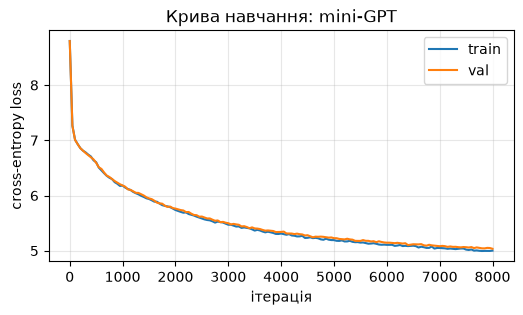

In [24]:
plt.figure(figsize=(6, 3))
plt.plot(checkpoint_iters, train_losses, label="train")
plt.plot(checkpoint_iters, val_losses, label="val")
plt.xlabel("ітерація"); plt.ylabel("cross-entropy loss"); plt.title("Крива навчання: mini-GPT")
plt.legend(); plt.grid(alpha=0.3)
plt.show()


### 3.10. Генерація на різних стадіях тренування

Порівнюємо якість тексту на першому збереженому чекпоінті (майже випадкова
ініціалізація) і на найкращому за val_loss (не обов'язково останньому —
модель могла почати переучуватись ближче до кінця тренування) — той самий
промпт в обох випадках.

In [25]:
def generate_text(state_dict_path: str, prompt: str, max_new_tokens: int = 40,
                   temperature: float = 0.8, top_k: int = 40) -> str:
    model.load_state_dict(torch.load(state_dict_path, map_location=device))
    prompt_ids = torch.tensor([encode(tokenize(prompt))], dtype=torch.long).to(device)
    out_ids = model.generate(prompt_ids, max_new_tokens, temperature=temperature, top_k=top_k)
    return decode(out_ids[0].tolist())


PROMPT = "Реве та стогне"

print("=== Ранній чекпоінт (iter", checkpoint_iters[0], ") ===")
print(generate_text(FIRST_CKPT_PATH, PROMPT))
print(f"\n=== Найкращий чекпоінт (iter {best_iter}, val_loss={best_val_loss:.3f}) ===")
print(generate_text(BEST_CKPT_PATH, PROMPT))

=== Ранній чекпоінт (iter 0 ) ===
Реве та стогне см�има розумію Ром виб людеуваличейпідлаличар повільноIII Левиту роботу Довмат історсутЧалось Невже панітах|овиклазску лиси дитина велика Щ разний цове сумно

=== Найкращий чекпоінт (iter 7999, val_loss=5.036) ===
Реве та стогне,
почно, як я за всесвіт
не сонце:
"Я сам, як ти,
золот, як же у мене ти?
Бо там, що я тобі


---
## 4. Sampling playground: готова модель

Власна mini-GPT замала, щоб переконливо демонструвати ефект temperature/
top-p — для цього візьмемо малу, але вже по-справжньому навчену відкриту
модель.

### 4.1. Завантажуємо готову модель

In [26]:
from transformers import AutoModelForCausalLM, AutoTokenizer

MODEL_ID = "Qwen/Qwen3-4B"

hf_tokenizer = AutoTokenizer.from_pretrained(MODEL_ID)
hf_model = AutoModelForCausalLM.from_pretrained(MODEL_ID, torch_dtype="auto").to(device)
hf_model.eval()

print("Модель завантажено:", MODEL_ID)
print("Параметрів:", sum(p.numel() for p in hf_model.parameters()) / 1e6, "млн")


tokenizer_config.json:   0%|          | 0.00/9.73k [00:00<?, ?B/s]

c:\Users\Dmytro\miniconda3\envs\bert-demo\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\Dmytro\.cache\huggingface\hub\models--Qwen--Qwen3-4B. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)


vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

c:\Users\Dmytro\miniconda3\envs\bert-demo\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\Dmytro\.cache\huggingface\hub. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)


tokenizer.json: reconstructing file:   0%|          |  0.00B / 11.4MB            

tokenizer.json: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

Модель завантажено: Qwen/Qwen3-4B
Параметрів: 4022.468096 млн


### 4.2. Той самий промпт, різна температура/top-p

Українська — не одна з офіційно заявлених мов цієї моделі, тому якість
може "плавати" — головне тут не ідеальність тексту, а те, як параметри
sampling міняють його характер.

In [27]:
def hf_generate(prompt: str, temperature: float, top_p: float, max_new_tokens: int = 300) -> str:
    messages = [{"role": "user", "content": prompt}]
    text = hf_tokenizer.apply_chat_template(
        messages, tokenize=False, add_generation_prompt=True, enable_thinking=True
    )
    inputs = hf_tokenizer([text], return_tensors="pt").to(device)

    outputs = hf_model.generate(
        **inputs,
        max_new_tokens=max_new_tokens,
        do_sample=True,
        temperature=temperature,
        top_p=top_p,
    )
    return hf_tokenizer.decode(outputs[0][inputs.input_ids.shape[-1]:], skip_special_tokens=True)


PLAYGROUND_PROMPT = "Продовж речення: Якось уночі студент " \
"Житомирської політехніки прокинувся від дивного шуму. Він підвівся з ліжка"

for temperature, top_p in [(0.2, 0.1), (0.8, 0.6), (1.4, 0.8)]:
    print(f"--- temperature={temperature}, top_p={top_p} ---")
    print(hf_generate(PLAYGROUND_PROMPT, temperature, top_p))
    print()

--- temperature=0.2, top_p=0.1 ---
<think>
Okay, the user wants me to continue the sentence: "Якось уночі студент Житомирської політехніки прокинувся від дивного шуму. Він підвівся з ліжка..." 

First, I need to make sure I understand the context. The sentence is in Ukrainian, so I should maintain the language. The story is about a student from the Kharkiv Polytechnic University (though the user wrote "Житомирської", which is Khmelnytskyi, but maybe it's a typo? Wait, no, "Житомирської" is Khmelnytskyi. But the user might have meant Kharkiv, but I should stick to the given name. Anyway, the main point is the student wakes up to a strange noise and gets up from bed.

The continuation should logically follow. The student hears a strange noise, gets up, maybe investigates. The next part should build on that. Maybe the noise is something unusual, like a sound from the building, or maybe something supernatural. Since it's a story, it could be a mystery or a supernatural element.

I need to 